# Phase 8 - Simulating games (Monte Carlo)

Code: `src/models/simulate.py`. Instead of picking a textbook distribution, we **play each game 2,000 times** in the computer:

```
expected minutes (ML model) + a realistic surprise   ->  minutes tonight
minutes x his shots-per-minute x "aggressiveness"    ->  2PA, 3PA, free-throw trips   (random counts)
each attempt x his make rate                         ->  makes                        (random coin flips)
2 x 2s + 3 x 3s + free throws                        ->  POINTS
```

**Monte Carlo** = answer a probability question by simulating it many times and counting.
"How often does he score 20+?" -> count how many of the 2,000 simulated games had 20+.

Part 2 of this notebook runs the model on the **2025-26 season** for **Dylan Harper** and four other players.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))
from src.evaluate import load_data, get_split
from src.models.simulate import GameSimulator
from src.models.distributions import DistributionModel, randomized_pit, K_MAX, POINTS

BLUE, ORANGE, AQUA, YELLOW, INK, INK_2 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110,
})
df = load_data()

# Part 1 - Does simulation beat the textbook shapes? (validation, 2024-25)

In [2]:
train, valid = get_split(df, "valid")
y = np.clip(valid["PTS"].to_numpy(), 0, K_MAX)
sim = GameSimulator().fit(train)
normal = DistributionModel("normal_scaled").fit(train)
negbin = DistributionModel("negbin").fit(train)
pmfs = {"Normal (Phase 6)": normal.pmf(valid), "Negative Binomial (Phase 6)": negbin.pmf(valid), "Simulation": sim.pmf(valid)}
colors = {"Normal (Phase 6)": ORANGE, "Negative Binomial (Phase 6)": AQUA, "Simulation": BLUE}

pd.read_csv("../results/simulation_scores.csv", index_col=0).round(4)

,LOG_SCORE,COVER_80,AVG_RANGE_WIDTH,BRIER_OVER,P(0 PTS),MAE (median)
model,,,,,,
"Normal, spread grows with mean (Phase 6)",-2.9994,0.7845,14.2025,0.2389,0.0881,4.4961
Negative Binomial (Phase 6),-3.0200,0.7909,14.7028,0.2375,0.0758,4.4810
"Simulation, pure basketball rates",-2.9508,0.7969,14.7676,0.2377,0.0976,4.5036
"Simulation, anchored to ML center",-2.9554,0.7980,14.5675,0.2364,0.1034,4.4647


The simulation wins on **log score** (-2.955 vs -2.999: a big jump for this metric), on over/under accuracy (Brier),
and its 80% ranges are the most honest (79.8%). Now the two weak spots from Phase 6:

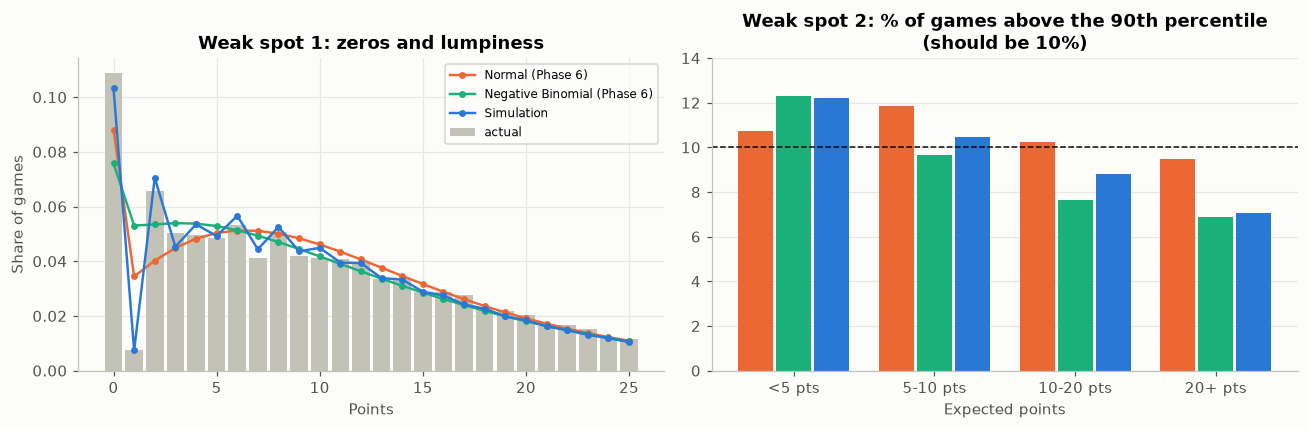

0-point games - actual 10.9%, Normal (Phase 6): 8.8%, Negative Binomial (Phase 6): 7.6%, Simulation: 10.3%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
actual = np.bincount(y, minlength=K_MAX + 1)[:26] / len(y)
ax.bar(POINTS[:26], actual, color="#c3c2b7", width=0.85, label="actual")
for name, pmf in pmfs.items():
    ax.plot(POINTS[:26], pmf.mean(axis=0)[:26], "o-", color=colors[name], markersize=3.5, linewidth=1.6, label=name)
ax.set(title="Weak spot 1: zeros and lumpiness", xlabel="Points", ylabel="Share of games")
ax.legend(fontsize=8)

ax = axes[1]
mu = normal._mu(valid)
tier = pd.cut(mu, [0, 5, 10, 20, 100], labels=["<5", "5-10", "10-20", "20+"])
x = np.arange(4)
for i, (name, pmf) in enumerate(pmfs.items()):
    pit = randomized_pit(pmf, y)
    high = pd.Series(pit > 0.9).groupby(tier, observed=True).mean() * 100
    ax.bar(x + (i - 1) * 0.27, high.values, width=0.25, color=colors[name], label=name)
ax.axhline(10, color=INK, linestyle="--", linewidth=1)
ax.set_xticks(x, [f"{t} pts" for t in high.index])
ax.set(title="Weak spot 2: % of games above the 90th percentile\n(should be 10%)", xlabel="Expected points", ylim=(0, 14))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"0-point games - actual {np.mean(y == 0):.1%}, " + ", ".join(f"{k}: {v[:, 0].mean():.1%}" for k, v in pmfs.items()))

**What this tells us:**
- **Zeros:** the simulation predicts ~10% (actual 10.9%), because it can simulate a 4-minute garbage-time night.
- **Lumpiness:** it also gets the rare 1-point games and common 2-point games right, *for free*, because free throws come in pairs
  and baskets are worth 2 or 3. Nobody told it that the distribution is lumpy - it falls out of the basketball logic.
- **Skew - not solved yet.** For stars, only ~7% of games beat the simulation's 90th percentile (should be 10%), about the same as the
  Negative Binomial. The simulation's top end is still a bit too generous for high scorers: stacking random minutes, random
  aggressiveness and random shots adds up to slightly too much upside. Honest result: better overall (best log score), but not perfect.

# Part 2 - Player reports: 2025-26 season

Now the fun part. We train on **2021-25** and predict every 2025-26 game for five players:

| Player | Why |
|---|---|
| **Dylan Harper** | Rookie (Spurs). Can the model handle a player with no NBA history? |
| **Cooper Flagg** | The other headline rookie - a featured scorer from day one |
| **Victor Wembanyama** | Harper's teammate - when he sits, does Harper's prediction rise? |
| **Shai Gilgeous-Alexander** | Elite, famously consistent scorer |
| **Stephen Curry** | 3-point-heavy -> expected to be the most volatile |

*Note: 2025-26 is our locked **test** season. We only **look** at these players here - nothing gets tuned on it.
The official, full test-set score is saved for Phase 10.*

In [4]:
full_train, test = get_split(df, "test")
sim_final = GameSimulator().fit(full_train)

PLAYERS = ["Dylan Harper", "Cooper Flagg", "Victor Wembanyama", "Shai Gilgeous-Alexander", "Stephen Curry"]
games = test[test["PLAYER_NAME"].isin(PLAYERS)].sort_values("GAME_DATE").reset_index(drop=True)
pmf = sim_final.pmf(games)
cdf = np.cumsum(pmf, axis=1)
games["pred_median"] = (cdf < 0.5).sum(axis=1)
games["pred_low"] = (cdf < 0.1).sum(axis=1)       # 10th percentile
games["pred_high"] = (cdf < 0.9).sum(axis=1)      # 90th percentile
games["p20plus"] = pmf[:, 20:].sum(axis=1)
games["in_range"] = games["PTS"].between(games["pred_low"], games["pred_high"])
print(f"{len(games)} games simulated")

304 games simulated


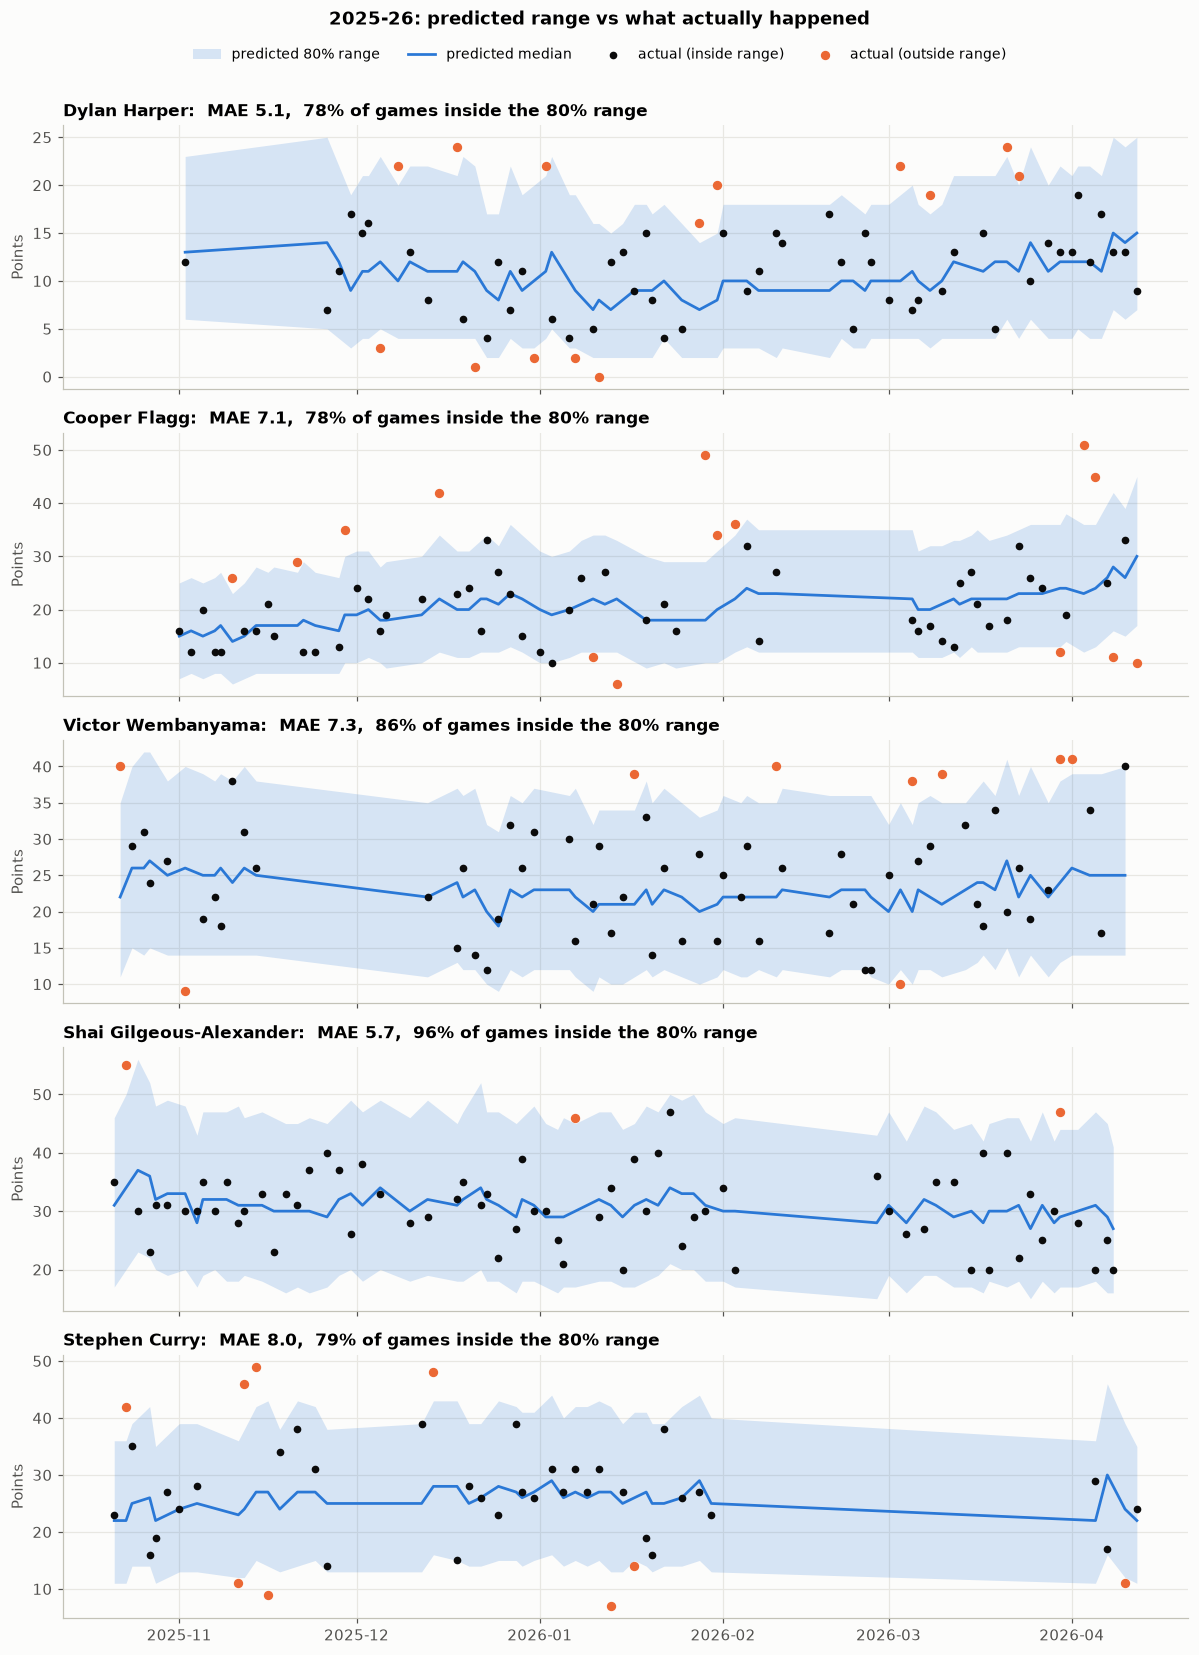

In [5]:
fig, axes = plt.subplots(len(PLAYERS), 1, figsize=(11, 3 * len(PLAYERS)), sharex=True)
for ax, name in zip(axes, PLAYERS):
    g = games[games["PLAYER_NAME"] == name]
    ax.fill_between(g["GAME_DATE"], g["pred_low"], g["pred_high"], color=BLUE, alpha=0.18, linewidth=0, label="predicted 80% range")
    ax.plot(g["GAME_DATE"], g["pred_median"], color=BLUE, linewidth=1.8, label="predicted median")
    inside = g["in_range"]
    ax.scatter(g.loc[inside, "GAME_DATE"], g.loc[inside, "PTS"], s=16, color=INK, zorder=3, label="actual (inside range)")
    ax.scatter(g.loc[~inside, "GAME_DATE"], g.loc[~inside, "PTS"], s=26, color=ORANGE, zorder=3, label="actual (outside range)")
    mae = np.mean(np.abs(g["PTS"] - g["pred_median"]))
    ax.set_title(f"{name}:  MAE {mae:.1f},  {inside.mean():.0%} of games inside the 80% range", loc="left", fontsize=11)
    ax.set_ylabel("Points")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.985), ncol=4, fontsize=9, frameon=False)
fig.suptitle("2025-26: predicted range vs what actually happened", fontweight="bold", y=1.0)
plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.show()

In [6]:
summary = games.groupby("PLAYER_NAME").agg(
    games=("PTS", "size"), actual_ppg=("PTS", "mean"), predicted_ppg=("pred_median", "mean"),
    MAE=("PTS", lambda s: np.mean(np.abs(s - games.loc[s.index, "pred_median"]))),
    inside_80_range=("in_range", "mean"),
).reindex(PLAYERS)
summary["MAE as % of ppg"] = summary["MAE"] / summary["actual_ppg"]
print(summary.round(3).to_string())

                         games  actual_ppg  predicted_ppg    MAE  inside_80_range  MAE as % of ppg
PLAYER_NAME                                                                                       
Dylan Harper                64      11.578         10.469  5.141            0.781            0.444
Cooper Flagg                65      21.631         20.446  7.092            0.785            0.328
Victor Wembanyama           64      25.000         22.953  7.297            0.859            0.292
Shai Gilgeous-Alexander     68      31.132         30.882  5.662            0.956            0.182
Stephen Curry               43      26.558         25.605  8.023            0.791            0.302


## Dylan Harper, up close

**Problem 1: no history.** Harper's first NBA games have no "last 10 games" to look at. Our project only predicts after a player's
5th game (`MIN_GAMES = 5`), and early on, his averages are based on very few games. How fast does the model catch up?

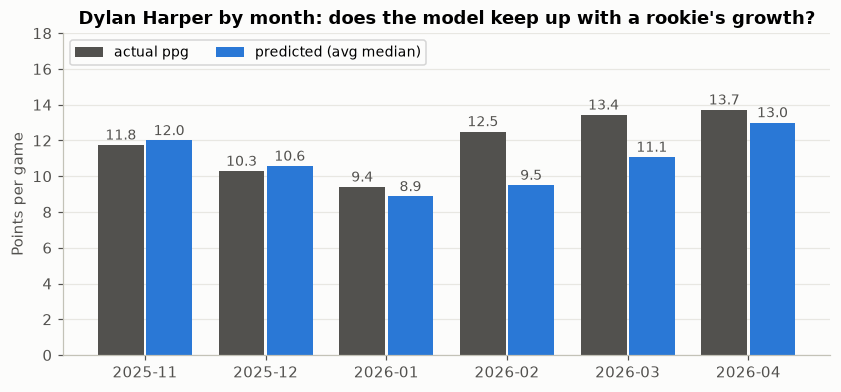

,games,actual,predicted,minutes,MAE
month,,,,,
2025-11,4,11.8,12.0,15.8,4.2
2025-12,14,10.3,10.6,21.1,6.1
2026-01,15,9.4,8.9,21.2,5.9
2026-02,10,12.5,9.5,25.1,4.2
2026-03,14,13.4,11.1,23.4,5.2
2026-04,7,13.7,13.0,24.9,3.3


In [7]:
h = games[games["PLAYER_NAME"] == "Dylan Harper"].copy()
h["game_no"] = h["GAMES_PLAYED_BEFORE"] + 1
h["abs_err"] = (h["PTS"] - h["pred_median"]).abs()
h["month"] = h["GAME_DATE"].dt.to_period("M").astype(str)

by_month = h.groupby("month").agg(games=("PTS", "size"), actual=("PTS", "mean"), predicted=("pred_median", "mean"),
                                  minutes=("MIN", "mean"), MAE=("abs_err", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(by_month))
ax.bar(x - 0.2, by_month["actual"], width=0.38, color=INK_2, label="actual ppg")
ax.bar(x + 0.2, by_month["predicted"], width=0.38, color=BLUE, label="predicted (avg median)")
for i, (a, p) in enumerate(zip(by_month["actual"], by_month["predicted"])):
    ax.text(i - 0.2, a + 0.3, f"{a:.1f}", ha="center", color=INK_2, fontsize=9)
    ax.text(i + 0.2, p + 0.3, f"{p:.1f}", ha="center", color=INK_2, fontsize=9)
ax.set_xticks(x, by_month.index)
ax.set(title="Dylan Harper by month: does the model keep up with a rookie's growth?", ylabel="Points per game", ylim=(0, 18))
ax.legend(fontsize=9, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()
by_month.round(1)

**What this tells us:** early on the model tracks him well. In **February-March** Harper's role grew (more minutes, 12.5-13.4 ppg)
and the model **lagged behind** by 2-3 points: it learns from his *past* games, so a rookie improving mid-season is always a step ahead
of it. By April it had caught up. (Also note: predictions here are **medians**, which sit slightly below averages for skewed
outcomes, so "predicted" should run a little under "actual" even for a perfect model.)

**Problem 2: playing next to Wembanyama.** When Wemby sits, someone has to take his shots. Our `TEAMMATES_OUT_PTS` feature should catch this.

In [8]:
wemby_games = set(test.loc[test["PLAYER_NAME"] == "Victor Wembanyama", "GAME_ID"])
h["wemby"] = np.where(h["GAME_ID"].isin(wemby_games), "Wembanyama played", "Wembanyama out")
split = h.groupby("wemby").agg(games=("PTS", "size"), actual_ppg=("PTS", "mean"), predicted_ppg=("pred_median", "mean"),
                               teammates_out=("TEAMMATES_OUT_PTS", "mean"), minutes=("MIN", "mean"))
split.round(1)

,games,actual_ppg,predicted_ppg,teammates_out,minutes
wemby,,,,,
Wembanyama out,14,13.3,12.1,25.0,22.6
Wembanyama played,50,11.1,10.0,10.6,22.3


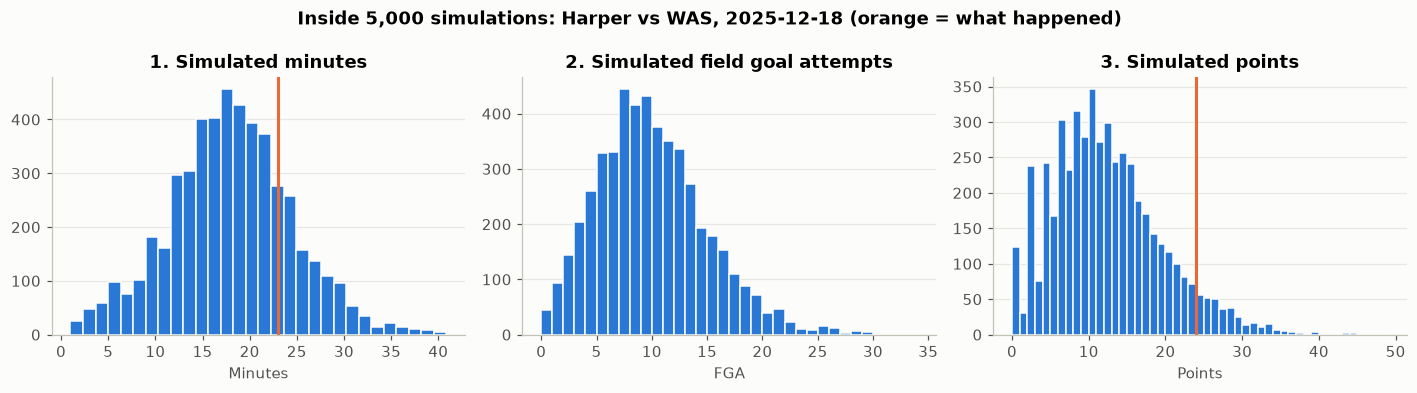

Simulated median 11, 80% range 4-21; P(24+ points) = 6.8%.  Actual: 24 points in 23 minutes.


In [9]:
row = h.loc[[h["PTS"].idxmax()]]
pts, parts = sim_final.simulate(row, n_sims=5000, return_parts=True)
r = row.iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(parts["minutes"][0], bins=30, color=BLUE, edgecolor="#fcfcfb")
axes[0].axvline(r["MIN"], color=ORANGE, linewidth=2)
axes[0].set(title="1. Simulated minutes", xlabel="Minutes")
axes[1].hist(parts["2PA"][0] + parts["3PA"][0], bins=range(0, 35), color=BLUE, edgecolor="#fcfcfb")
axes[1].set(title="2. Simulated field goal attempts", xlabel="FGA")
axes[2].hist(pts[0], bins=range(0, 50), color=BLUE, edgecolor="#fcfcfb")
axes[2].axvline(r["PTS"], color=ORANGE, linewidth=2)
axes[2].set(title="3. Simulated points", xlabel="Points")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Inside 5,000 simulations: Harper vs {r['OPPONENT']}, {r['GAME_DATE'].date()} (orange = what happened)", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Simulated median {np.median(pts):.0f}, 80% range {np.percentile(pts, 10):.0f}-{np.percentile(pts, 90):.0f}; "
      f"P({r['PTS']}+ points) = {np.mean(pts >= r['PTS']):.1%}.  Actual: {r['PTS']} points in {r['MIN']} minutes.")

**What this tells us:** with Wemby out, ~25 ppg worth of teammates are missing (vs ~11) and Harper scored **+2.2 more points**.
The model raised its prediction by **+2.1** - it picked up the effect almost exactly, without ever being told who Wembanyama is.

The last chart shows the simulation's three stages for Harper's best game (24 pts vs WAS): plenty of minutes and shots,
but 24 was in the top ~7% of simulated outcomes - a genuinely great night, not something the model "should" have predicted.

## Summary

**Simulation vs textbook distributions (2024-25 validation):**
- Best log score yet (-2.955 vs -2.999), best over/under accuracy, most honest 80% ranges (79.8%)
- Gets 0-point games (10.3% vs actual 10.9%) and the lumpiness of real scoring right - from basketball logic, not curve fitting
- Still slightly too generous at the top end for stars - room to improve

**2025-26 player reports:**

| Player | MAE | Inside 80% range | Takeaway |
|---|---|---|---|
| Dylan Harper | 5.1 | 78% | Honest ranges; lagged 2-3 pts behind his mid-season growth; caught the Wembanyama-out boost almost exactly |
| Cooper Flagg | 7.1 | 78% | Rookie who kept improving - big nights late in the season beat the range |
| Victor Wembanyama | 7.3 | 86% | High-variance star; ranges slightly too wide |
| Shai Gilgeous-Alexander | 5.7 | **96%** | Most consistent star - ranges were **too wide** for him. Lowest error relative to his scoring (~18%) |
| Stephen Curry | 8.0 | 79% | Most volatile, as expected for a 3-point-heavy scorer: misses in both directions |

**Lessons:**
1. **Rookies are a step behind by design** - the model learns from past games, so fast improvement shows up late.
2. **Teammate absences matter and the model handles them** - Harper's Wembanyama-out boost was predicted within 0.1 points.
3. **One-size-fits-all spread is the next thing to fix** - SGA's ranges should be narrower, Curry's wider. A player's own
   consistency is only partly captured.

**Next (Phase 9): neural networks** - built from scratch first, then with PyTorch, including **player embeddings**:
a learned "fingerprint" per player, which could capture exactly this kind of player-specific behavior.